In [1]:
import sys
from pathlib import Path

ROOT = Path().resolve().parent

sys.path.insert(0, str(ROOT / "results" / "evaluation" ))

In [4]:
import pickle
import pandas as pd

path = ROOT / "results" / "evaluation" / "real_life"
rl_complexity_path = path / "complexity.csv"
rl_quality_path = path / "quality.csv"

rl_c_df = pd.read_csv(rl_complexity_path)
rl_q_df = pd.read_csv(rl_quality_path)

rl_df_merge = pd.merge(rl_c_df, rl_q_df, on="name", how="inner")
rl_df = rl_df_merge[["name", "complexity_avg_raw_std", "complexity_avg_norm_std", "complexity_div_std", "complexity_disp_std",  "complexity_diss_aa_seq_std",
                     "f_score_imtf", "f_score_imts", "f_score_imto", "f_score_imftf", "f_score_imfts", "f_score_imfto"]]
rl_df

,name,complexity_avg_raw_std,complexity_avg_norm_std,complexity_div_std,complexity_disp_std,complexity_diss_aa_seq_std,f_score_imtf,f_score_imts,f_score_imto,f_score_imftf,f_score_imfts,f_score_imfto
0,BPIC 12 A,-0.154923,-0.167488,1.286198,2.015005,1.808069,0.539207,0.539207,0.243423,0.689196,0.689196,0.416228
1,BPIC 12 O,-0.622845,0.157384,1.028602,2.691605,1.643130,0.826087,0.826087,0.575758,0.826087,0.826087,0.775510
2,BPIC 12 W,-1.024360,-0.926246,1.028602,1.017759,0.712468,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
3,BPIC 13 Closed Problems,-0.518436,2.165405,0.169947,0.628173,-0.077836,0.857737,0.962351,0.857737,0.807151,0.925432,0.807151
4,BPIC 13 Incidents,-0.578992,0.799547,1.028602,1.667836,3.164910,0.814815,0.936170,0.814815,0.814815,0.936170,0.814815
5,BPIC 13 Open Problems,-0.359729,2.940092,-1.547361,-0.960494,-0.893695,0.791569,0.791569,0.791569,0.791569,0.791569,0.791569
6,BPIC 17 Offer,-0.744336,-0.654216,-0.903370,-0.673724,-0.713484,0.960763,0.960763,0.960763,0.960763,0.960763,0.960763
7,BPIC 19 2-way Match,-0.734832,-0.640961,-0.516976,-0.434249,-0.425220,0.903704,0.903704,0.903704,0.903704,0.903704,0.903704
8,BPIC 19 Consignment,0.413875,0.123951,1.672592,-0.282127,-0.308110,0.751893,0.868701,0.751893,0.869847,0.869206,0.869847
9,BPIC 20 Domestic Declarations,-0.380806,-0.581323,-1.179366,-0.750011,-0.677702,0.980356,1.000000,0.980356,0.753246,1.000000,0.753246


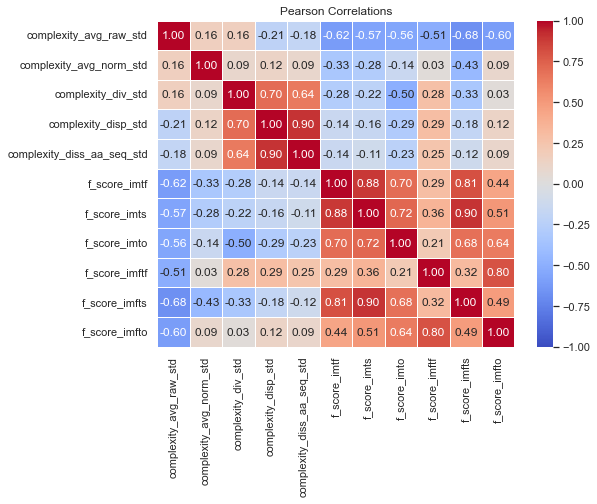

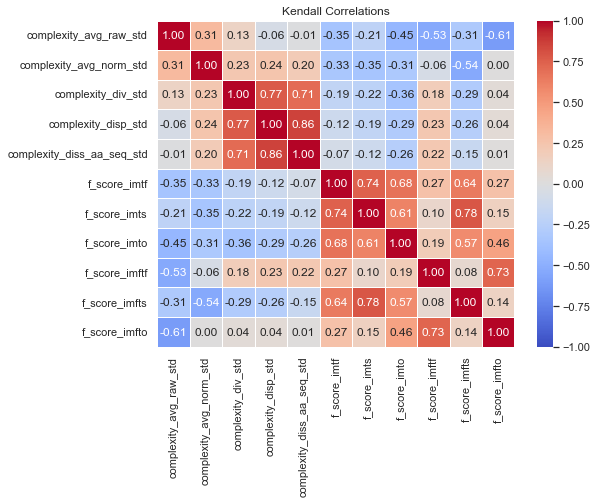

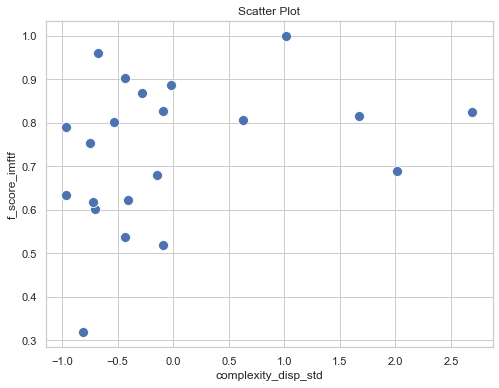

In [10]:
from scipy.stats import kendalltau, pearsonr
import matplotlib.pyplot as plt
import seaborn as sns

def get_p_values(df, method="pearson"):
  cols = df.columns
  p_val_df = pd.DataFrame(np.zeros((len(cols), len(cols))), index=cols, columns=cols)

  for i in range(len(cols)):
    for j in range(len(cols)):
      if i == j:
        p_val_df.iloc[i, j] = 0.0
      else:
        if method == "pearson":
          _, p_val = pearsonr(df.iloc[:, i], df.iloc[:, j])
        elif method == "kendall":
          _, p_val = kendalltau(df.iloc[:, i], df.iloc[:, j])
        p_val_df.iloc[i, j] = p_val

  return p_val_df

p_corr = rl_df.drop(columns=["name"]).corr(method="pearson")
k_corr = rl_df.drop(columns=["name"]).corr(method="kendall")

def show_heatmap(corr, title):
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        fmt=".2f",
        linewidths=0.5,
    )
    
    plt.title(title)
    plt.show()

def show_scatterplot(df, x, y, title):
    sns.set_theme(style="whitegrid")
    
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        palette="deep",
        s=100,
    )
    
    plt.title(title)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.show()

show_heatmap(p_corr, "Pearson Correlations")
show_heatmap(k_corr, "Kendall Correlations")

show_scatterplot(rl_df, "complexity_disp_std", "f_score_imftf", "Scatter Plot")

In [5]:
path_t = ROOT / "results" / "translucent_real_life" / "BPIC 19 2-way Match.pkl"
path_c = ROOT / "results" / "translucent_real_life" / "BPIC 19 Consignment.pkl"

with open(path_t, "rb") as f:
    log_t = pickle.load(f)

with open(path_c, "rb") as f:
    log_c = pickle.load(f)

log_t["name"] = "BPIC 19 2-way Match"
log_c["name"] = "BPIC 19 Consignment"

with open(path_t, "wb") as f:
    pickle.dump(log_t, f)

with open(path_c, "wb") as f:
    pickle.dump(log_c, f)

In [6]:
path = ROOT / "results" / "translucent_real_life" / "BPIC 19 Consignment.pkl"

with open(path, "rb") as f:
    log = pickle.load(f)

print(log)

{'name': 'BPIC 19 Consignment', 'dataframe':            User org:resource                concept:name  \
0      user_060     user_060  Create Purchase Order Item   
1      user_031     user_031        Record Goods Receipt   
2      user_060     user_060  Create Purchase Order Item   
3      user_031     user_031        Record Goods Receipt   
4      user_060     user_060  Create Purchase Order Item   
...         ...          ...                         ...   
16116  user_258     user_258        Record Goods Receipt   
16117  user_088     user_088        Record Goods Receipt   
16118  user_363     user_363        Record Goods Receipt   
16119  user_407     user_407   Change Delivery Indicator   
16120  user_087     user_087        Record Goods Receipt   

       Cumulative net worth (EUR)            time:timestamp  \
0                             0.0 2018-05-29 15:34:00+00:00   
1                             0.0 2018-06-08 07:46:00+00:00   
2                             0.0 2018-05-29 